In [242]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("C:\KubaMagisterka\south+german+credit+update\SouthGermanCredit.asc", sep = " ", engine = "python")

[Text(0, 0, '300'), Text(0, 0, '700')]

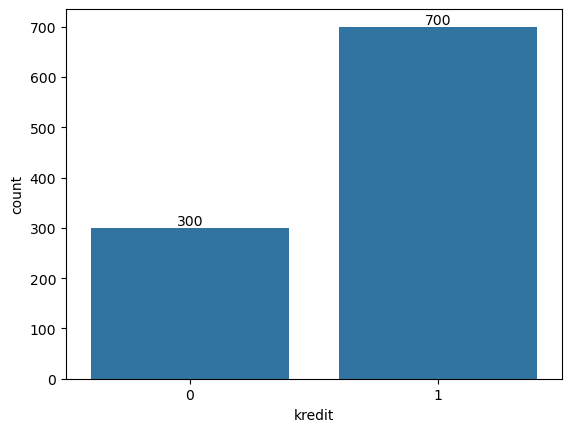

In [243]:
ax = sns.countplot(data = df, x = 'kredit')
ax.bar_label(ax.containers[0])

In [244]:
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata

In [245]:
metadata = Metadata.detect_from_dataframe(df)

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(df[df["kredit"] == 0])

synthetic_data_0 = synthesizer.sample(num_rows = 400)

C:\Users\kinga\anaconda3\Lib\site-packages\sdv\single_table\base.py:134: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



In [246]:
len(synthetic_data_0[synthetic_data_0["kredit"] == 0])

400

In [247]:
df = pd.concat([synthetic_data_0, df], axis = 0)

In [248]:
df = df.sample(frac = 1).reset_index(drop = True)

In [249]:
mapping_colnames = {
    
    "laufkont":"stan_konta",
    "laufzeit":"czas_zapadalności_kredytu",
    "moral":"historia_kredytowa",
    "verw":"cel_kredytu",
    "hoehe":"wielkość_kredytu",
    "sparkont":"oszczędności",
    "beszeit":"czas_zatrudnienia",
    "rate":"wysokość_raty_kredytu",
    "famges":"status_matrymonialny",
    "buerge":"inni_kredytobiorcy",
    "wohnzeit":"miejsce_zamieszkania",
    "verm":"najdroższa_własność",
    "alter":"wiek",
    "weitkred":"inne_kredyty",
    "wohn":"sposób_opłaty_mieszkania",
    "bishkred":"liczba_kredytów_w_historii",
    "beruf":"praca",
    "pers":"liczba_osób_na_utrzymaniu",
    "telef":"telefon",
    "gastarb":"cudzoziemiec",
    "kredit":"ryzyko_kredytowe"
    
}

In [250]:
df.rename(columns = mapping_colnames, inplace = True)

In [251]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_o

In [252]:
df['cel_kredytu'].unique()

array([ 3,  2,  0,  1,  5,  9,  4,  6, 10,  8])

In [253]:
df['wielkość kredytu / czas spłaty'] = df['wielkość_kredytu'] / df['czas_zapadalności_kredytu']

In [254]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   int64  
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   int64  
 3   cel_kredytu                     1400 non-null   int64  
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   int64  
 6   czas_zatrudnienia               1400 non-null   int64  
 7   wysokość_raty_kredytu           1400 non-null   int64  
 8   status_matrymonialny            1400 non-null   int64  
 9   inni_kredytobiorcy              1400 non-null   int64  
 10  miejsce_zamieszkania            1400 non-null   int64  
 11  najdroższa_własność             1400 non-null   int64  
 12  wiek                            14

In [255]:
#mapping_colnames = dict(np.array(credit_approval.variables[["name", "description"]]))

In [256]:
#df.rename(columns = mapping_colnames, inplace = True)
#df.rename(columns = {'1 = Good, 0 = Bad' : 'class'}, inplace = True)

In [257]:
#df.info()

In [258]:
df.describe(exclude = "object")

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,...,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,2.397143,22.181429,2.427857,2.903571,3479.517857,1.992143,3.353571,3.005000,2.652143,1.135000,...,34.568571,2.634286,1.923571,1.393571,2.908571,1.854286,1.379286,1.970000,0.500000,166.960440
std,1.244628,12.411399,1.086901,2.899062,2999.275355,1.526257,1.212274,1.120019,0.726105,0.453314,...,11.501606,0.735476,0.561336,0.578469,0.663722,0.352946,0.485383,0.170648,0.500179,147.412820
min,1.000000,4.000000,0.000000,0.000000,250.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,19.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,13.204545
25%,1.000000,12.000000,2.000000,0.000000,1364.000000,1.000000,3.000000,2.000000,2.000000,1.000000,...,26.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000,83.566667
50%,2.000000,19.000000,2.000000,2.000000,2440.000000,1.000000,3.000000,3.000000,3.000000,1.000000,...,32.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.500000,130.648810
75%,4.000000,29.000000,3.250000,3.000000,4493.000000,3.000000,4.000000,4.000000,3.000000,1.000000,...,40.250000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,211.708333
max,4.000000,72.000000,4.000000,10.000000,18424.000000,5.000000,5.000000,4.000000,4.000000,3.000000,...,75.000000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000,2482.666667


In [259]:
def describe_advanced(data):
    
    data = np.asarray(data)
    
    return {
        "max": np.max(data),
        "min": np.min(data),
        "dominanta": stats.mode(data).mode[0],
        "kurtoza": np.round(stats.kurtosis(data), 2),
        "skośność": np.round(stats.skew(data), 2),
        "średnia": np.round(np.mean(data), 2),
        "odchylenie standardowe": np.round(np.std(data), 2),
        "współczynnik zmienności": np.round(np.round(np.std(data), 2) / np.round(np.mean(data), 2), 2)
    }

In [260]:
num_cols = ['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek', 'wielkość kredytu / czas spłaty']

In [261]:
cat_cols = []

for i in df.columns:
    if i not in num_cols:
        cat_cols.append(i)

In [262]:
cat_cols.remove("ryzyko_kredytowe")
df[cat_cols] = df[cat_cols].astype("object")

In [263]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   object 
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   object 
 3   cel_kredytu                     1400 non-null   object 
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   object 
 6   czas_zatrudnienia               1400 non-null   object 
 7   wysokość_raty_kredytu           1400 non-null   object 
 8   status_matrymonialny            1400 non-null   object 
 9   inni_kredytobiorcy              1400 non-null   object 
 10  miejsce_zamieszkania            1400 non-null   object 
 11  najdroższa_własność             1400 non-null   object 
 12  wiek                            14

[Text(0, 0, '700'), Text(0, 0, '700')]

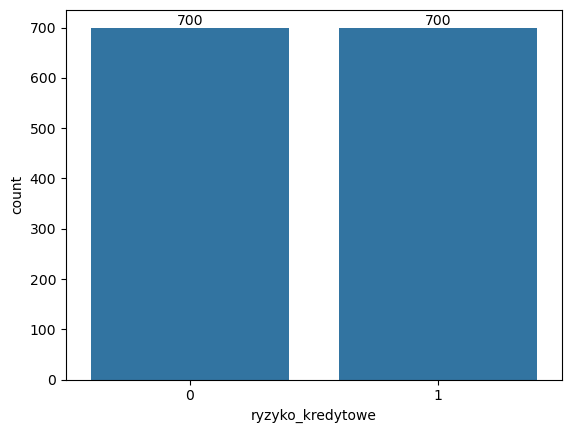

In [264]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [265]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(df[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [266]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,72.000000,4.000000,24.000000,[0.67],[1.01],22.18,12.41,0.56
wielkość_kredytu,18424.000000,250.000000,458.000000,[3.1],[1.73],3479.52,2998.20,0.86
wiek,75.000000,19.000000,23.000000,[0.65],[1.05],34.57,11.50,0.33
wielkość kredytu / czas spłaty,2482.666667,13.204545,63.833333,[84.7],[6.51],166.96,147.36,0.88


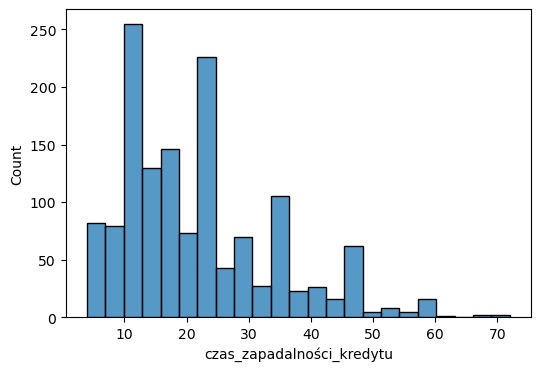

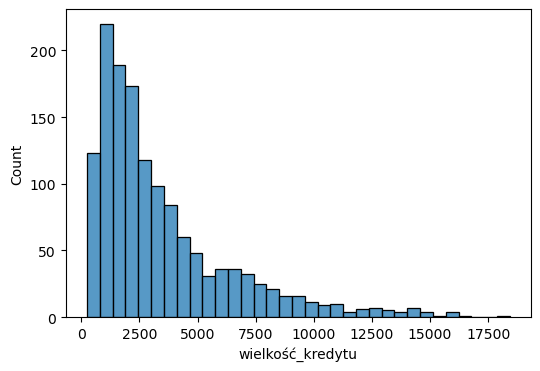

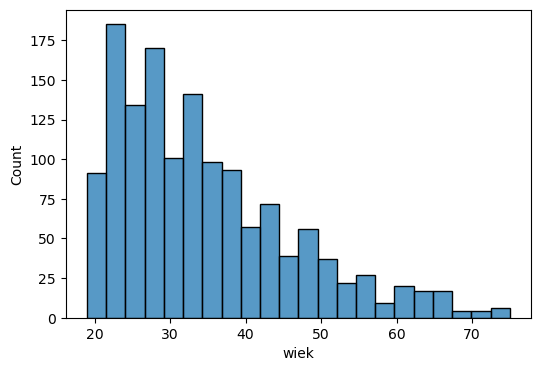

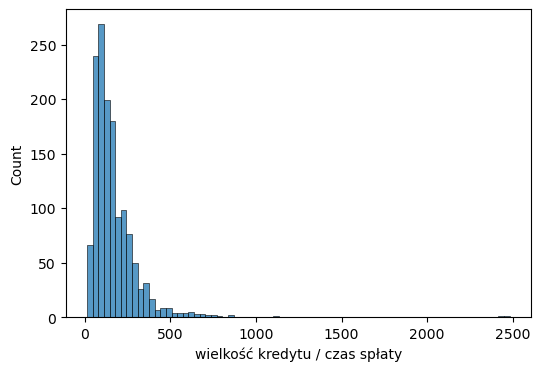

In [267]:
for i in num_cols:
     plt.figure(figsize=(6, 4))
     histograms = sns.histplot(df[i])
     plt.show()

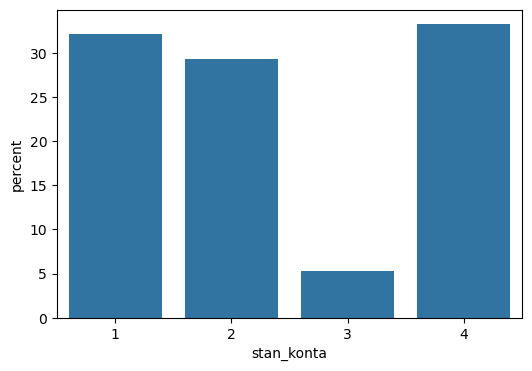

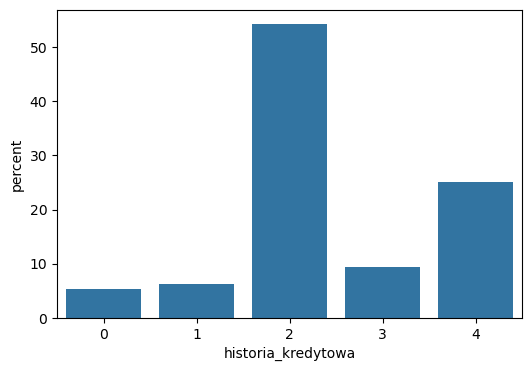

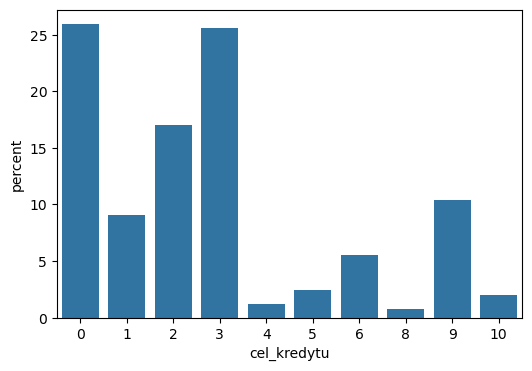

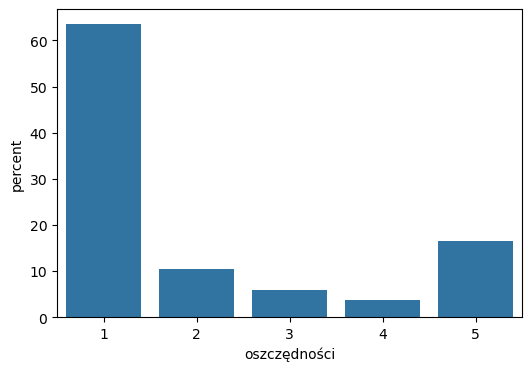

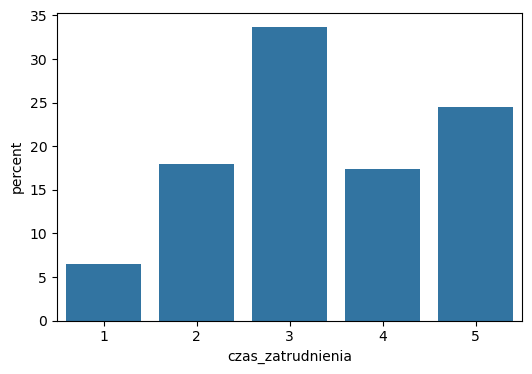

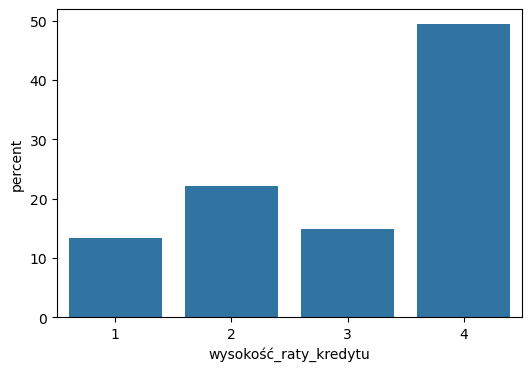

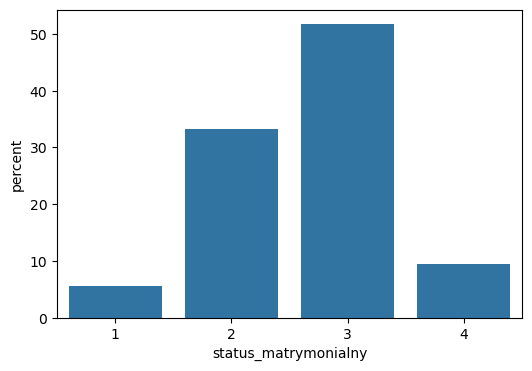

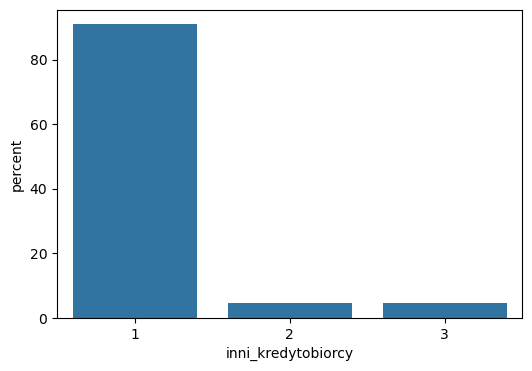

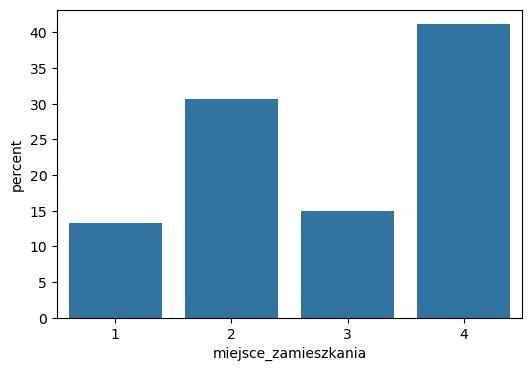

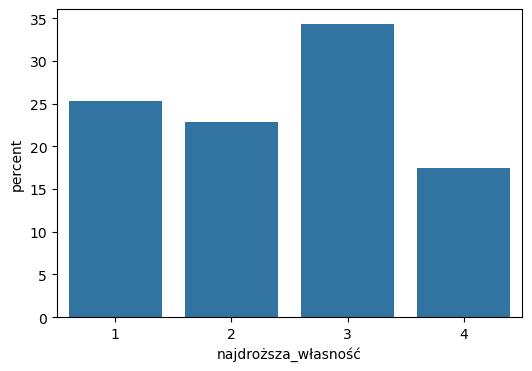

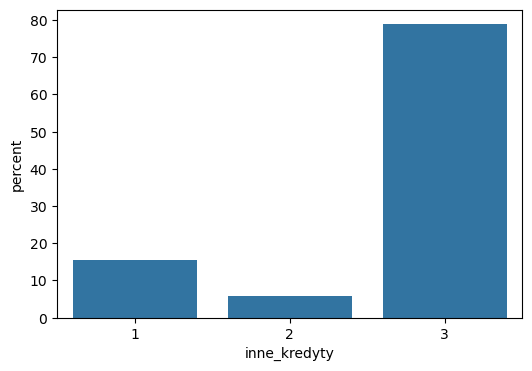

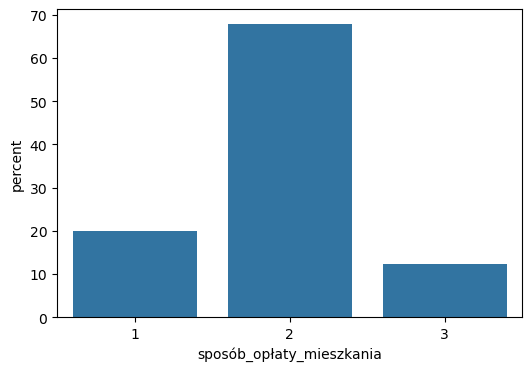

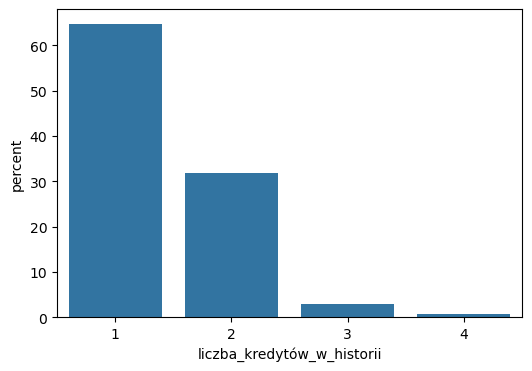

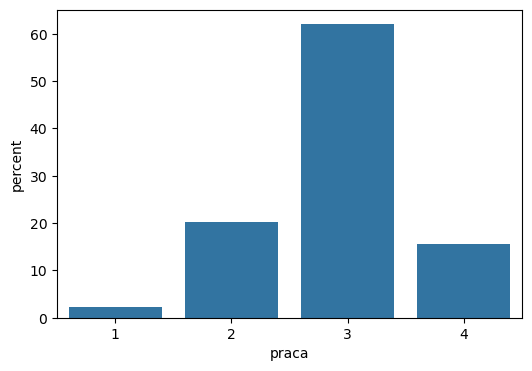

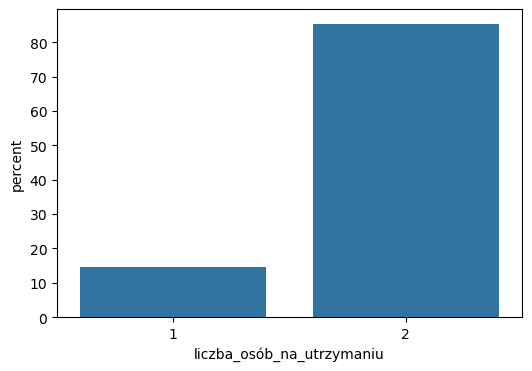

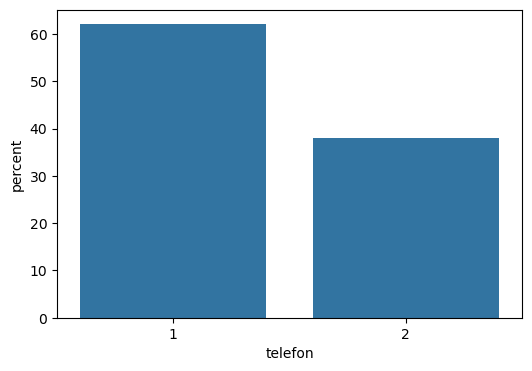

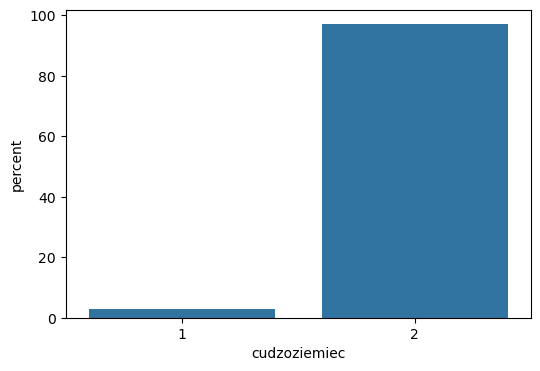

In [268]:
for i in cat_cols:
     plt.figure(figsize=(6, 4))
     countplots = sns.countplot(x = df[i], stat = "percent")
     plt.show()

In [269]:
scores = []

for i in cat_cols:
        name = i
        percent = df[i].value_counts() / len(df) * 100
        
        for category, percent in percent.items():
            scores.append({
                "Variable" : i,
                "Category": category,
                "Percent": percent
            })

In [270]:
scores = pd.DataFrame(scores)

In [271]:
scores.set_index("Variable", inplace = True)

In [272]:
scores.sort_values(by = ["Variable", "Category"], inplace = True)

In [273]:
print(scores.to_string())

                            Category    Percent
Variable                                       
cel_kredytu                        0  25.928571
cel_kredytu                        1   9.071429
cel_kredytu                        2  17.000000
cel_kredytu                        3  25.571429
cel_kredytu                        4   1.214286
cel_kredytu                        5   2.428571
cel_kredytu                        6   5.571429
cel_kredytu                        8   0.785714
cel_kredytu                        9  10.428571
cel_kredytu                       10   2.000000
cudzoziemiec                       1   3.000000
cudzoziemiec                       2  97.000000
czas_zatrudnienia                  1   6.500000
czas_zatrudnienia                  2  18.000000
czas_zatrudnienia                  3  33.642857
czas_zatrudnienia                  4  17.357143
czas_zatrudnienia                  5  24.500000
historia_kredytowa                 0   5.214286
historia_kredytowa                 1   6

In [274]:
scores["Percent"].sum()

np.float64(1699.9999999999998)

<Axes: >

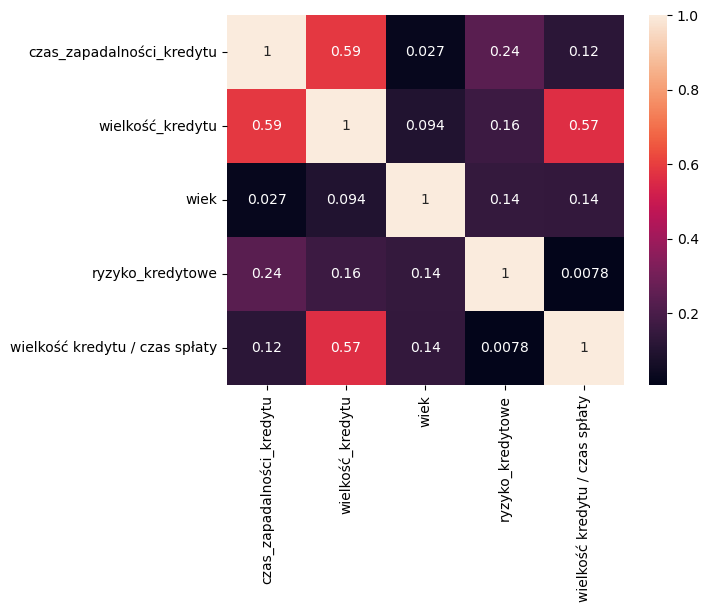

In [275]:
sns.heatmap(df.corr(numeric_only = True).abs(), annot = True)

In [276]:
#df.drop("Duration", axis = 1, inplace = True)

In [277]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   object 
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   object 
 3   cel_kredytu                     1400 non-null   object 
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   object 
 6   czas_zatrudnienia               1400 non-null   object 
 7   wysokość_raty_kredytu           1400 non-null   object 
 8   status_matrymonialny            1400 non-null   object 
 9   inni_kredytobiorcy              1400 non-null   object 
 10  miejsce_zamieszkania            1400 non-null   object 
 11  najdroższa_własność             1400 non-null   object 
 12  wiek                            14

In [278]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
0,4,22,2,3,2675,3,5,3,3,1,...,40,3,2,1,3,2,1,2,1,121.590909
1,1,18,2,2,2659,4,3,4,3,1,...,28,3,2,1,3,2,1,2,1,147.722222
2,4,24,2,0,5332,1,4,1,1,2,...,38,1,2,2,3,2,2,2,0,222.166667
3,1,21,4,0,1602,1,5,4,4,1,...,30,3,2,2,3,2,2,2,1,76.285714
4,1,25,2,1,4022,1,3,4,4,1,...,27,3,2,1,4,2,1,2,0,160.880000


In [279]:
from sklearn.preprocessing import OneHotEncoder

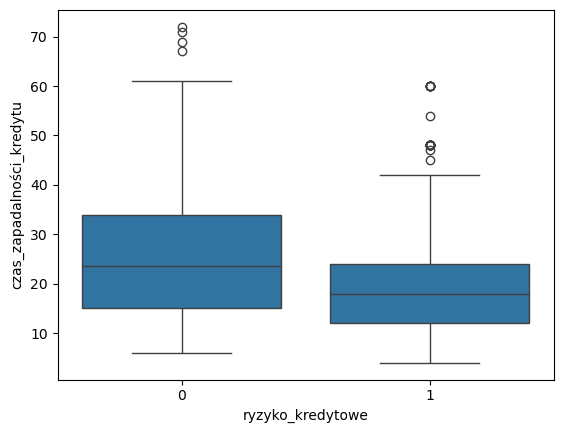

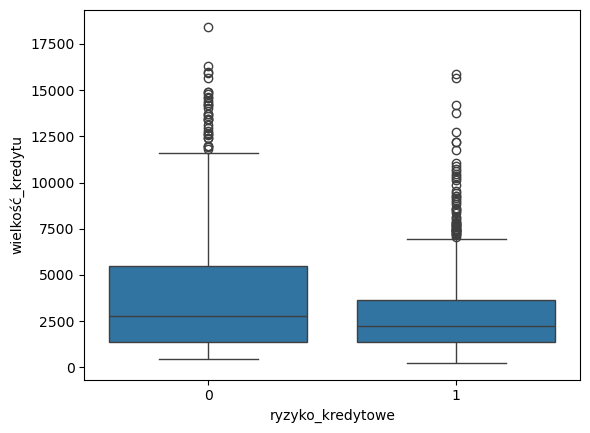

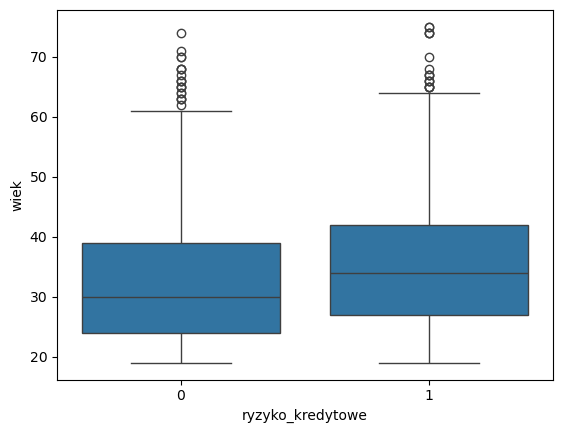

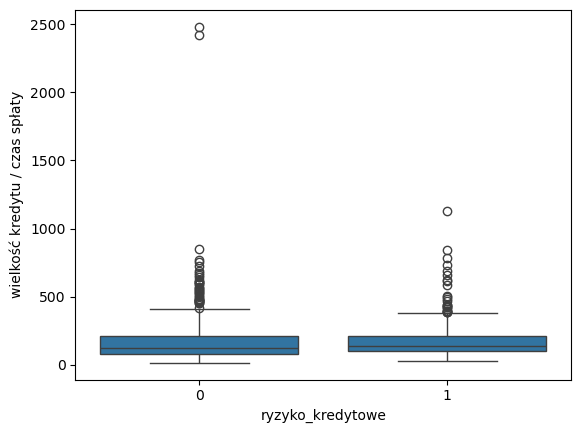

In [280]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [281]:
for i in num_cols:
    q_treshold = df[i].quantile(0.99)
    df = df[df[i] <= q_treshold]

In [282]:
num_cols

['czas_zapadalności_kredytu',
 'wielkość_kredytu',
 'wiek',
 'wielkość kredytu / czas spłaty']

In [283]:
cat_cols

['stan_konta',
 'historia_kredytowa',
 'cel_kredytu',
 'oszczędności',
 'czas_zatrudnienia',
 'wysokość_raty_kredytu',
 'status_matrymonialny',
 'inni_kredytobiorcy',
 'miejsce_zamieszkania',
 'najdroższa_własność',
 'inne_kredyty',
 'sposób_opłaty_mieszkania',
 'liczba_kredytów_w_historii',
 'praca',
 'liczba_osób_na_utrzymaniu',
 'telefon',
 'cudzoziemiec']

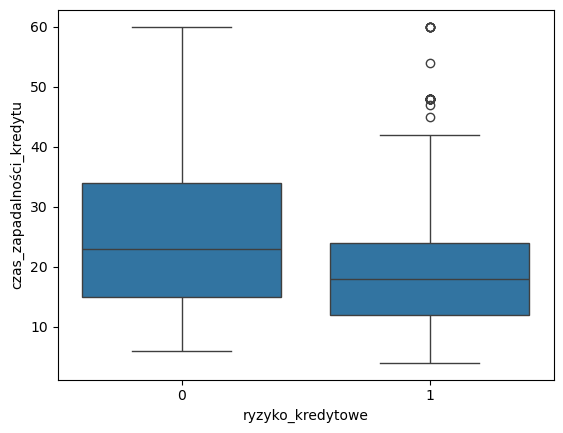

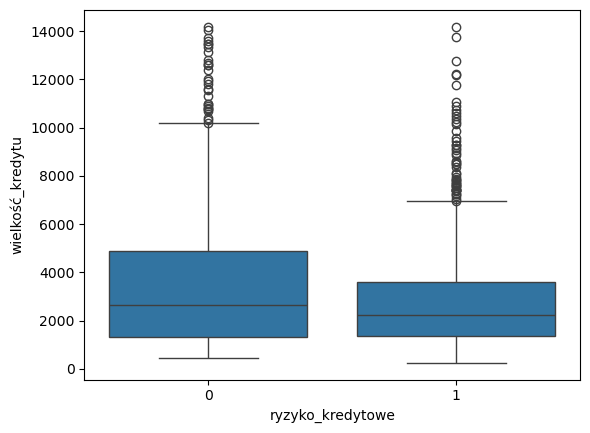

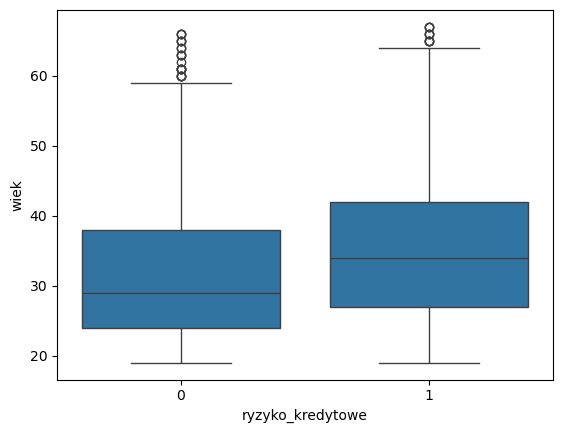

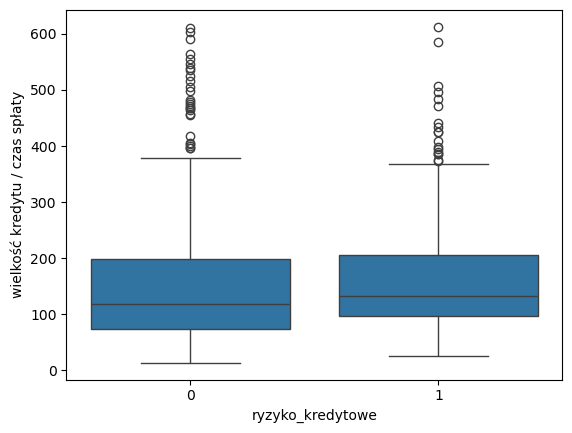

In [284]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [285]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1354 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1354 non-null   object 
 1   czas_zapadalności_kredytu       1354 non-null   int64  
 2   historia_kredytowa              1354 non-null   object 
 3   cel_kredytu                     1354 non-null   object 
 4   wielkość_kredytu                1354 non-null   int64  
 5   oszczędności                    1354 non-null   object 
 6   czas_zatrudnienia               1354 non-null   object 
 7   wysokość_raty_kredytu           1354 non-null   object 
 8   status_matrymonialny            1354 non-null   object 
 9   inni_kredytobiorcy              1354 non-null   object 
 10  miejsce_zamieszkania            1354 non-null   object 
 11  najdroższa_własność             1354 non-null   object 
 12  wiek                            1354 no

In [286]:
sum(df.duplicated())

0

In [287]:
df.reset_index(inplace = True, drop = True)

In [288]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
0,4,22,2,3,2675,3,5,3,3,1,...,40,3,2,1,3,2,1,2,1,121.590909
1,1,18,2,2,2659,4,3,4,3,1,...,28,3,2,1,3,2,1,2,1,147.722222
2,4,24,2,0,5332,1,4,1,1,2,...,38,1,2,2,3,2,2,2,0,222.166667
3,1,21,4,0,1602,1,5,4,4,1,...,30,3,2,2,3,2,2,2,1,76.285714
4,1,25,2,1,4022,1,3,4,4,1,...,27,3,2,1,4,2,1,2,0,160.880000


In [289]:
from sklearn.model_selection import train_test_split

X = df.drop("ryzyko_kredytowe", axis = 1)
y = df["ryzyko_kredytowe"]

[Text(0, 0, '668'), Text(0, 0, '686')]

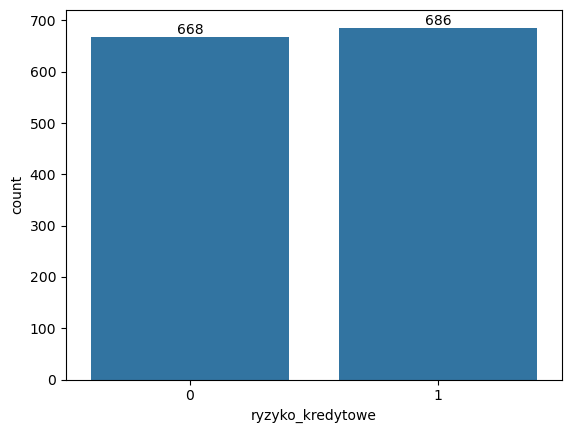

In [290]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [291]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1354 entries, 0 to 1353
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1354 non-null   object 
 1   czas_zapadalności_kredytu       1354 non-null   int64  
 2   historia_kredytowa              1354 non-null   object 
 3   cel_kredytu                     1354 non-null   object 
 4   wielkość_kredytu                1354 non-null   int64  
 5   oszczędności                    1354 non-null   object 
 6   czas_zatrudnienia               1354 non-null   object 
 7   wysokość_raty_kredytu           1354 non-null   object 
 8   status_matrymonialny            1354 non-null   object 
 9   inni_kredytobiorcy              1354 non-null   object 
 10  miejsce_zamieszkania            1354 non-null   object 
 11  najdroższa_własność             1354 non-null   object 
 12  wiek                            13

In [292]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [293]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(X_train[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [294]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,60.000000,4.000000,24.000000,[0.32],[0.91],21.76,11.73,0.54
wielkość_kredytu,14179.000000,250.000000,458.000000,[2.37],[1.59],3255.59,2648.03,0.81
wiek,67.000000,19.000000,23.000000,[0.34],[0.95],34.07,10.84,0.32
wielkość kredytu / czas spłaty,612.666667,13.204545,63.833333,[2.29],[1.38],155.38,97.91,0.63


In [295]:
pos_label, neg_label = 1, 0

In [296]:
#from imblearn.over_sampling import SMOTE

In [297]:
from sklearn.preprocessing import StandardScaler

In [298]:
from sklearn.linear_model import LogisticRegression

In [299]:
from sklearn.metrics import ConfusionMatrixDisplay

In [300]:
from sklearn.compose import ColumnTransformer

def transform_data(X_train, num_cols, cat_cols, ttype):
    num_transformer = StandardScaler()

    cat_transformer = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    if ttype == 'all':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'cat':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'num':
         preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', 'passthrough', cat_cols)
            ],
            remainder='drop'
        )
    else:
        print("wrong param")
    
    X_train_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()
    
    X_train = pd.DataFrame(
        X_train_transformed, 
        columns = feature_names, 
        index = X_train.index
    )
    
    return preprocessor

In [301]:
def united_shapley(shap_ohe):
    feature_groups = {}
    
    for i in df.columns:
        div_columns = [j[5:] for j in X_train_transformed_df.columns if j[5:].startswith(i)]
        feature_groups[i] = div_columns
    
    if shap_ohe.values.ndim == 3:
        current_values = shap_ohe.values[:, :, 1].copy()
        current_base_values = shap_ohe.base_values[:, 1].copy()
    elif shap_ohe.values.ndim == 2:
        current_values = shap_ohe.values.copy()
        current_base_values = shap_ohe.base_values.copy()
    
    current_feature_names = [
        name[5:] if name.startswith(('num__', 'cat__')) else name 
        for name in shap_ohe.feature_names
    ]
    
    for group_name, sum_columns in feature_groups.items():
        indx = [current_feature_names.index(c) for c in sum_columns if c in current_feature_names]
    
        if indx:
            sum_shap = current_values[:, indx].sum(axis = 1)
    
            for i in sorted(indx, reverse = True):
                current_values = np.delete(current_values, i, axis = 1)
                current_feature_names.pop(i)
    
            current_values = np.c_[current_values, sum_shap]
            current_feature_names.append(group_name)
    
    new_shap_values = shap.Explanation(
            values = current_values,
            base_values = current_base_values,
            data =  X_train.values,
            feature_names = current_feature_names
        )
    
    return new_shap_values

In [302]:
#https://medium.com/@ravi.abhinav4/improving-class-imbalance-with-class-weights-in-machine-learning-af072fdd4aa4
def calculate_class_weights(y):
    unique_classes, class_counts = np.unique(y, return_counts=True)
    total_samples = len(y)
    class_weights = {}

    for class_label, class_counts in zip(unique_classes, class_counts):
        class_weight = total_samples / (2.0 * class_counts)
        class_weights[class_label] = class_weight

    class_weight0 = class_weights[0]
    class_weight1 = class_weights[1]

    print(f'Weight for class 0: ', class_weight0)
    print(f'Weight for class 1: ', class_weight1)

In [303]:
calculate_class_weights(y)

Weight for class 0:  1.0134730538922156
Weight for class 1:  0.9868804664723032


In [304]:
class_weights = {0: 1.7017543859649122, 1: 0.708029197080292}

In [305]:
from sklearn.model_selection import LearningCurveDisplay, RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 10, random_state = 42)

In [306]:
from sklearn.model_selection import TunedThresholdClassifierCV

In [307]:
from imblearn.pipeline import Pipeline

In [308]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from sklearn.model_selection import ShuffleSplit

def lower_bound(cv_results):
    best_score_idx = np.argmax(cv_results["mean_test_neg_brier_score"])
    return (
        cv_results["mean_test_neg_brier_score"][best_score_idx]
        - cv_results["std_test_neg_brier_score"][best_score_idx])

def best_low_complexity(cv_results):
    threshold = lower_bound(cv_results)
    candidate_idx = np.flatnonzero(cv_results["mean_test_neg_brier_score"] >= threshold)
    best_idx = candidate_idx[
        cv_results["param_reduce_dim__n_components"][candidate_idx].argmin()
    ]
    return best_idx

In [309]:
from sklearn.metrics import confusion_matrix

def fpr_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    tn, fp, _, _ = cm.ravel()
    tnr = tn / (tn + fp)
    return 1 - tnr

In [310]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score

tpr_score = recall_score  # TPR and recall are the same metric
scr = {
    "precision": make_scorer(precision_score, pos_label=pos_label, zero_division = 0),
    "recall": make_scorer(recall_score, pos_label=pos_label),
    "bad_recall" : make_scorer(recall_score, pos_label=pos_label, zero_division = 0),
    "fpr": make_scorer(fpr_score, neg_label=neg_label, pos_label=pos_label,  greater_is_better = False),
    "tpr": make_scorer(tpr_score, pos_label=pos_label),
    'accuracy': make_scorer(accuracy_score, neg_label=neg_label, pos_label=pos_label)
}

In [311]:
import numpy as np

def credit_gain_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])

    gain_matrix = np.array(
        [
            [0, -1],
            [-5, 0],
        ]
    )
    return np.sum(cm * gain_matrix)


scr["credit_gain"] = make_scorer(
    credit_gain_score, neg_label=neg_label, pos_label=pos_label
)

In [312]:
lr = LogisticRegression(random_state = 42, class_weight = "balanced")

In [313]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1083 entries, 1 to 333
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1083 non-null   object 
 1   czas_zapadalności_kredytu       1083 non-null   int64  
 2   historia_kredytowa              1083 non-null   object 
 3   cel_kredytu                     1083 non-null   object 
 4   wielkość_kredytu                1083 non-null   int64  
 5   oszczędności                    1083 non-null   object 
 6   czas_zatrudnienia               1083 non-null   object 
 7   wysokość_raty_kredytu           1083 non-null   object 
 8   status_matrymonialny            1083 non-null   object 
 9   inni_kredytobiorcy              1083 non-null   object 
 10  miejsce_zamieszkania            1083 non-null   object 
 11  najdroższa_własność             1083 non-null   object 
 12  wiek                            1083 non

In [314]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import FixedThresholdClassifier

clf_lr = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LogisticRegression(random_state = 42, class_weight = "balanced"))])

In [327]:
from scipy.stats import randint, loguniform

param_distributions = [{'classifier__C': loguniform(0.1, 1),
               'classifier__solver': ['liblinear'],
               'classifier__penalty': ['l1', 'l2'],
               'classifier__max_iter' : [1000, 1500]}]

In [328]:
from sklearn.metrics import fbeta_score

In [329]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

model = RandomizedSearchCV(clf_lr, 
                           param_distributions = param_distributions, 
                           cv = cv, 
                           n_jobs = 1, 
                           refit = 'recall', 
                           n_iter = 10, 
                           scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                           return_train_score = True, 
                           random_state = 42)

In [330]:
model.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"[{'classifier__C': <scipy.stats....00282F7328750>, 'classifier__max_iter': [1000, 1500], 'classifier__penalty': ['l1', 'l2'], 'classifier__solver': ['liblinear']}]"
,n_iter,10
,scoring,"['recall', 'accuracy', ...]"
,n_jobs,1
,refit,'recall'
,cv,RepeatedStrat...ndom_state=42)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [331]:
best_model = model.best_estimator_

In [332]:
results = pd.DataFrame(model.cv_results_)

In [333]:
from sklearn.metrics import PrecisionRecallDisplay, auc, precision_recall_curve, f1_score

In [334]:
def cv_cm(cv_object, y_train):
    total_train_obs = y_train.shape[0]
    cv_results = pd.DataFrame(cv_object.cv_results_)
    best_estimator_results = cv_results.iloc[cv_results['mean_test_recall'].idxmax(), :]

    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    true_positives = ((precision * recall) * (total_train_obs - (accuracy * total_train_obs))) / (recall - (2 * recall * precision) + precision)
    false_positives = round((true_positives - (precision * true_positives)) / precision, 0)
    false_negatives = round((true_positives - (recall * true_positives)) / recall, 0)

    print(f'accuracy: ', accuracy)
    print(f'recall: ', recall)
    print(f'precision: ', precision)
    
    true_negatives = round((accuracy * total_train_obs) - true_positives, 0)
    true_positives = round(true_positives, 0)

    prediction_list = [true_negatives, false_positives, false_negatives, true_positives]
    prediction_matrix = np.array(prediction_list).reshape(2, 2)

    plt.figure(figsize = (5, 4))
    ax = sns.heatmap(prediction_matrix, vmin = 0, vmax = total_train_obs, annot = True,
                    cmap = sns.color_palette('Spectral', as_cmap = True), fmt = 'g')
    plt.title('Confusion Matrix', fontsize = 16)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    return plt.show()
    return cv_results

accuracy:  0.7531033452807647
recall:  0.7461134278565471
precision:  0.7630376731174533


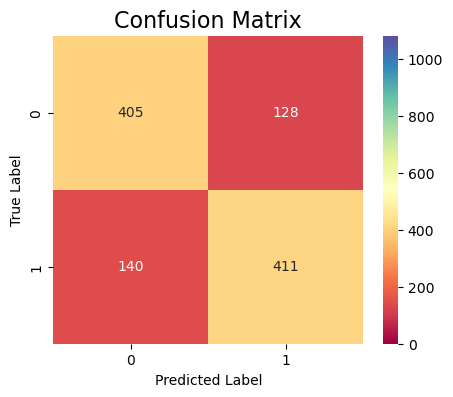

In [335]:
cv_cm(model, y_train)

In [336]:
#https://stackoverflow.com/questions/73582838/what-is-predict-proba-and-1-after-x-test-in-code
#column index 0 => negative class predictions
#column index 1 => positive class predictions

def set_threshold(chosen_model):
    y_scores = chosen_model.predict_proba(X_test)[:, 1]
    
    precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
    auc_score = auc(recall, precision)
    
    with np.errstate(divide='ignore', invalid='ignore'):
        f1s = 2 * (precision * recall) / (precision + recall)
        f1s[np.isnan(f1s)] = 0  
    
    best_thresh = thresholds[f1s.argmax()]
    print("Best threshold:", best_thresh)
    
    y_pred_reg_opt = (y_scores >= best_thresh).astype(int)
    return y_pred_reg_opt

In [337]:
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import cross_validate

def roc_cv(best_model):
    n_splits = 5
    cv = 5
    cv_results = cross_validate(
        best_model, X, y, cv=cv, return_estimator=True, return_indices=True
    )
    
    prop_cycle = plt.rcParams["axes.prop_cycle"]
    colors = prop_cycle.by_key()["color"]
    curve_kwargs_list = [
        dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
    ]
    names = [f"ROC fold {idx}" for idx in range(n_splits)]
    
    mean_fpr = np.linspace(0, 1, 100)
    interp_tprs = []
    
    _, ax = plt.subplots(figsize=(6, 6))
    viz = RocCurveDisplay.from_cv_results(
        cv_results,
        X,
        y,
        ax=ax,
        name=names,
        curve_kwargs=curve_kwargs_list,
        plot_chance_level=True,
    )
    
    for idx in range(n_splits):
        interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
        interp_tpr[0] = 0.0
        interp_tprs.append(interp_tpr)
    
    mean_tpr = np.mean(interp_tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(viz.roc_auc)
    
    ax.plot(
        mean_fpr,
        mean_tpr,
        color="b",
        label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
        lw=2,
        alpha=0.8,
    )
    
    std_tpr = np.std(interp_tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax.fill_between(
        mean_fpr,
        tprs_lower,
        tprs_upper,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )
    
    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate"
    )
    ax.legend(loc="lower right")
    plt.show()

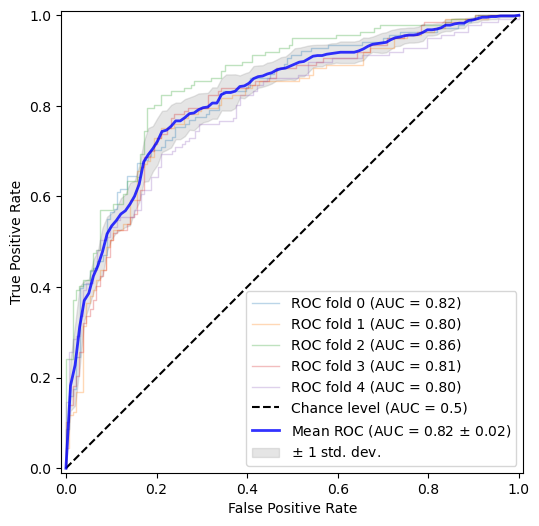

In [338]:
roc_cv(best_model)

In [339]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

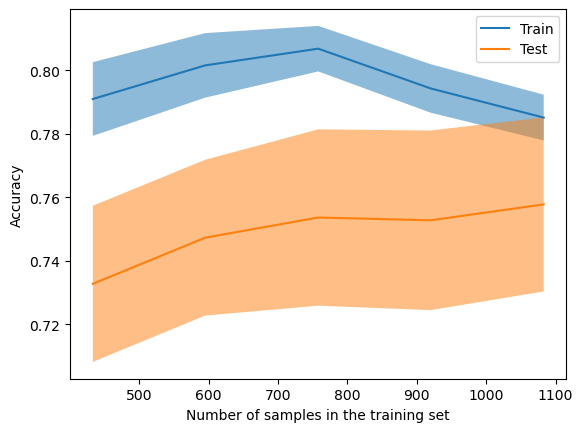

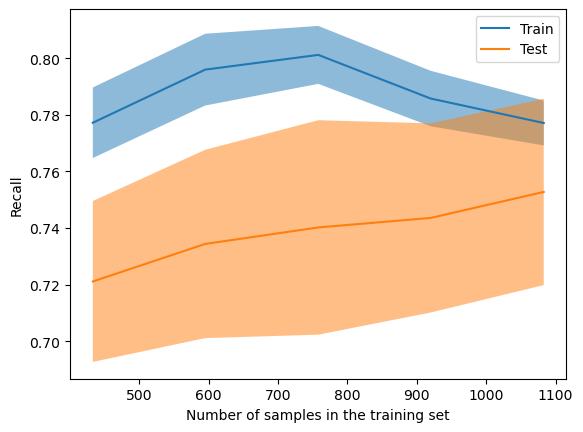

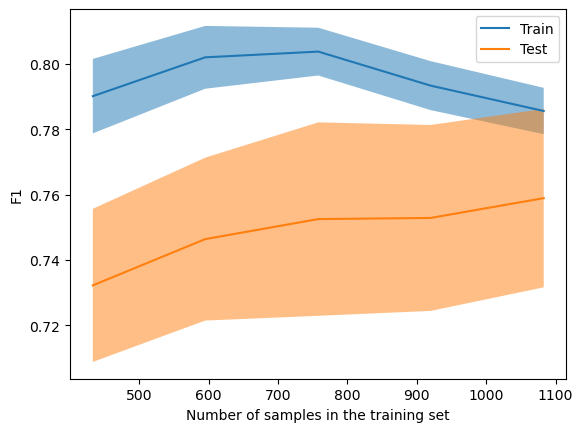

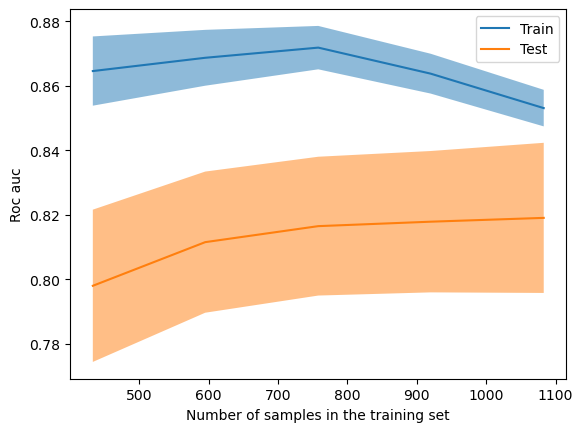

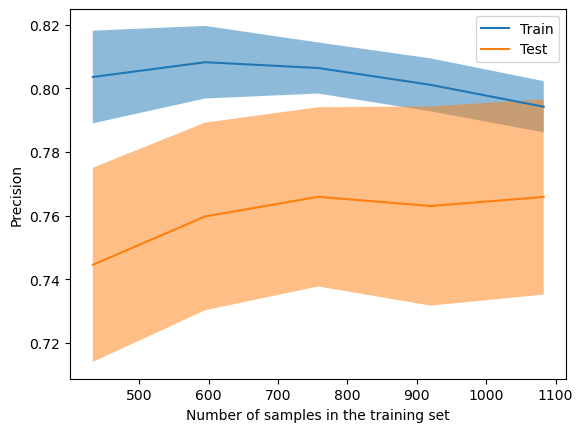

In [340]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_model, X, y, scoring = i, cv = cv, train_sizes = train_sizes, error_score = "raise")

In [341]:
from sklearn.model_selection import cross_val_score

def model_evaluation(estimator):

    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats = 5, random_state=42)
    metrics = {"accuracy", "roc_auc", "f1", "precision", "recall"}
    
    for i in metrics:
        scores = cross_val_score(estimator, X, y, scoring=i, cv=cv)
        
        print("Mean " + i + ":", scores.mean())
        print("Standard deviation:", scores.std())
        print("\n")

In [342]:
model_evaluation(best_model)

Mean accuracy: 0.7571622249555829
Standard deviation: 0.02788869737597381


Mean recall: 0.7516005500899187
Standard deviation: 0.03254649650445328


Mean f1: 0.7581919242346267
Standard deviation: 0.027817944357012053


Mean roc_auc: 0.8196187995531536
Standard deviation: 0.021763346564580233


Mean precision: 0.765573052050617
Standard deviation: 0.031586450910590085




In [343]:
import shap

In [344]:
best_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [345]:
best_model = best_model.named_steps['classifier']

In [346]:
fitted_preprocessor = clf_lr.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [347]:
explainer = shap.Explainer(best_model, X_train_transformed_df, model_output = 'probability')
shap_values_ohe = explainer(X_train_transformed_df)
shap_values = united_shapley(shap_values_ohe)

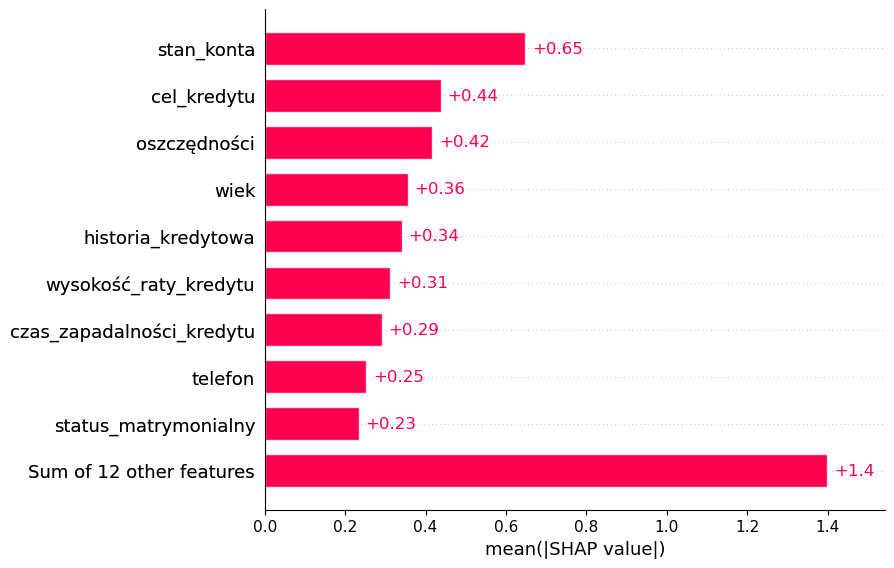

In [348]:
shap.plots.bar(shap_values)

In [349]:
X_train.head(1)

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,wielkość kredytu / czas spłaty
1,1,18,2,2,2659,4,3,4,3,1,...,3,28,3,2,1,3,2,1,2,147.722222


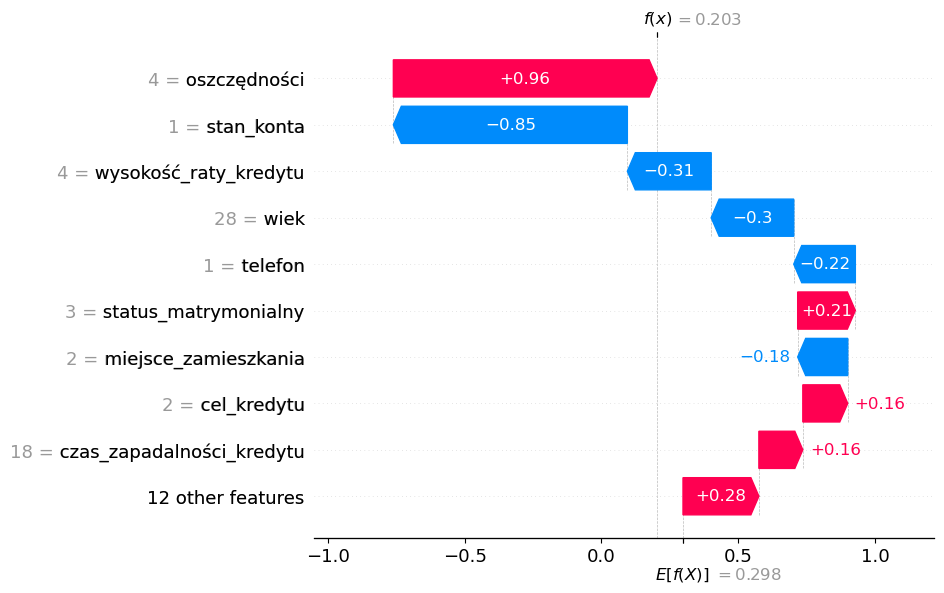

In [351]:
shap.plots.waterfall(shap_values[0], max_display=10, show=True)

In [352]:
from sklearn.metrics import brier_score_loss

In [353]:
y_scores = best_model.predict_proba(X_test_transformed)[:, 1]

In [354]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.17889118449195254

In [355]:
y_predicted = best_model.predict(X_test_transformed)

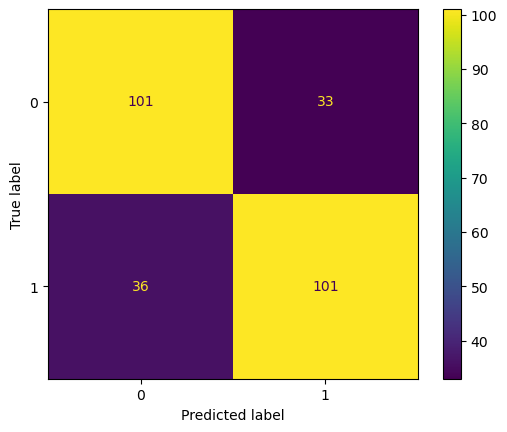

In [356]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [357]:
accuracy_score(y_test, y_predicted)

0.7453874538745388

In [358]:
recall_score(y_test, y_predicted)

0.7372262773722628

In [359]:
precision_score(y_test, y_predicted)

0.753731343283582

In [360]:
from sklearn.metrics import brier_score_loss

In [226]:
from sklearn.svm import LinearSVC

In [227]:
from imblearn.pipeline import Pipeline

In [109]:
np.random.seed(42)
clf_svc = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LinearSVC(random_state = 42))])

In [412]:
from scipy.stats import randint, loguniform

param_distributions = {
    'classifier__C': loguniform(0.1, 1),
    'classifier__penalty': ['l1', 'l2'],
    'classifier__max_iter' : [1000, 1500],
    'classifier__dual': [False]
}

In [415]:
model_svc = RandomizedSearchCV(clf_svc, 
                              param_distributions = param_distributions, 
                              scoring = ['precision', 'recall', 'accuracy', 'f1', 'balanced_accuracy'],
                              n_iter = 10,
                              n_jobs = 1, 
                              cv = cv, 
                              random_state = 42, 
                              refit = 'balanced_accuracy')

In [416]:
model_svc.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__C': <scipy.stats....0028291D45B50>, 'classifier__dual': [False], 'classifier__max_iter': [1000, 1500], 'classifier__penalty': ['l1', 'l2']}"
,n_iter,10
,scoring,"['precision', 'recall', ...]"
,n_jobs,1
,refit,'balanced_accuracy'
,cv,RepeatedStrat...ndom_state=42)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [417]:
pd.DataFrame(model_svc.cv_results_)[['rank_test_precision', 'mean_test_precision', 'std_test_precision']].sort_values(by = "rank_test_precision")

,rank_test_precision,mean_test_precision,std_test_precision
5,1,0.761232,0.032418
8,2,0.759776,0.031108
1,3,0.759502,0.031563
0,4,0.759164,0.030951
6,5,0.759054,0.031996
9,6,0.758968,0.031652
7,7,0.758604,0.031467
4,8,0.758500,0.031686
2,9,0.758499,0.031360
3,10,0.757802,0.034635


In [418]:
best_svc = model_svc.best_estimator_

In [419]:
y_pred_best = best_svc.predict(X_test)

In [420]:
y_scores = best_svc.predict(X_test)

accuracy:  0.7516248506571088
recall:  0.7493861551292743
precision:  0.7590543194807792


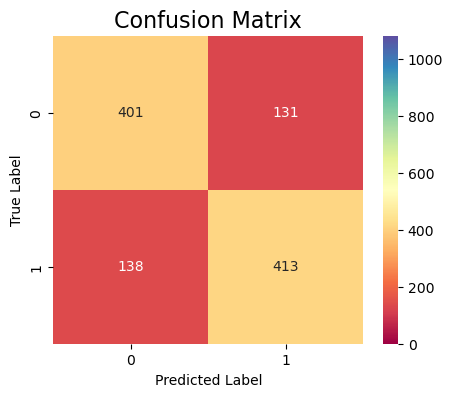

In [421]:
cv_cm(model_svc, y_train)

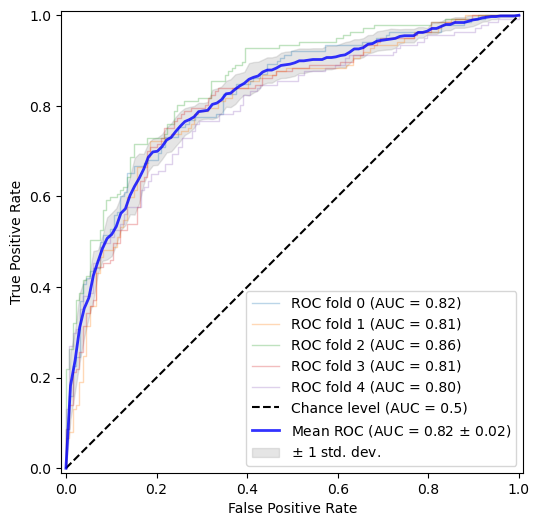

In [411]:
roc_cv(model_svc)

In [389]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

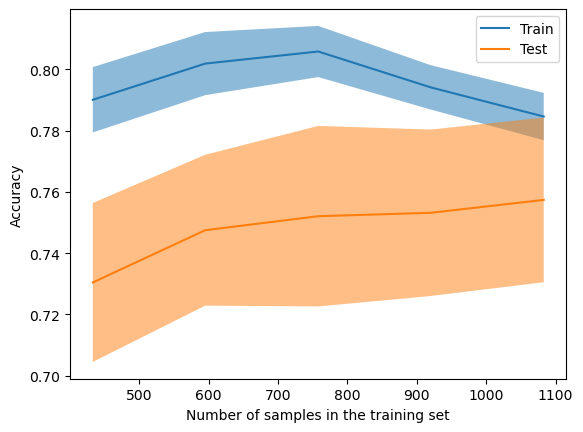

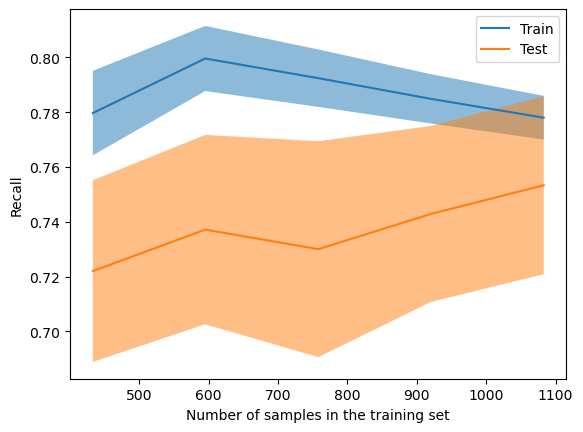

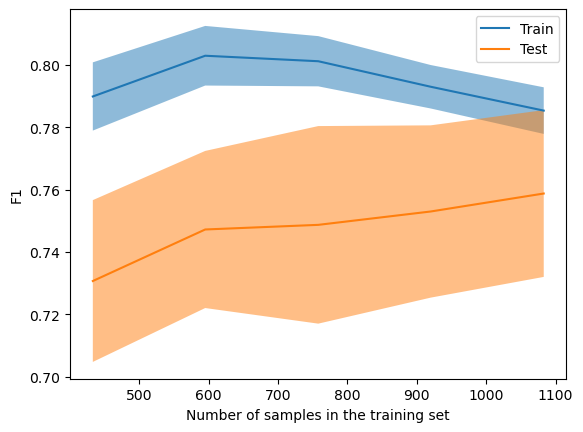

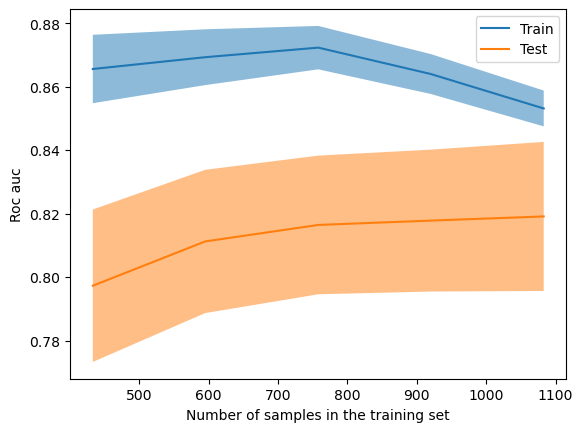

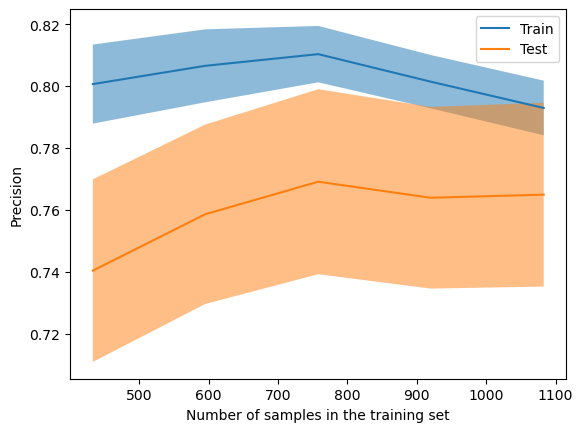

In [390]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_svc, X, y, scoring = i, cv = cv, train_sizes = train_sizes)

In [391]:
model_evaluation(best_svc)

Mean accuracy: 0.7565718190515238
Standard deviation: 0.02789577047782602


Mean recall: 0.7521950703480377
Standard deviation: 0.03400172702327161


Mean f1: 0.7578517897411043
Standard deviation: 0.028027773118623568


Mean roc_auc: 0.8198638557961238
Standard deviation: 0.02194014343738933


Mean precision: 0.7643015957921792
Standard deviation: 0.03085758251127551




In [392]:
best_svc.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [393]:
best_svc = best_svc.named_steps['classifier']

In [394]:
fitted_preprocessor = clf_svc.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.fit_transform(X_train)
X_test_transformed = fitted_preprocessor.fit_transform(X_test)

In [395]:
feature_names = fitted_preprocessor.get_feature_names_out()

In [396]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [397]:
svc_explainer = shap.Explainer(best_svc, X_train_transformed_df)
svc_shap_values = svc_explainer(X_train_transformed_df)
svc_shap_values = united_shapley(svc_shap_values)

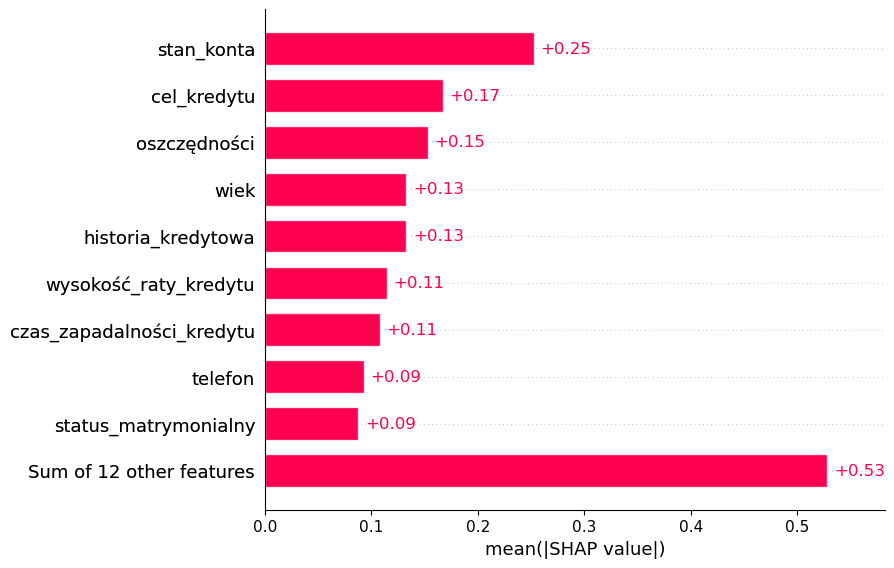

In [398]:
shap.plots.bar(svc_shap_values)

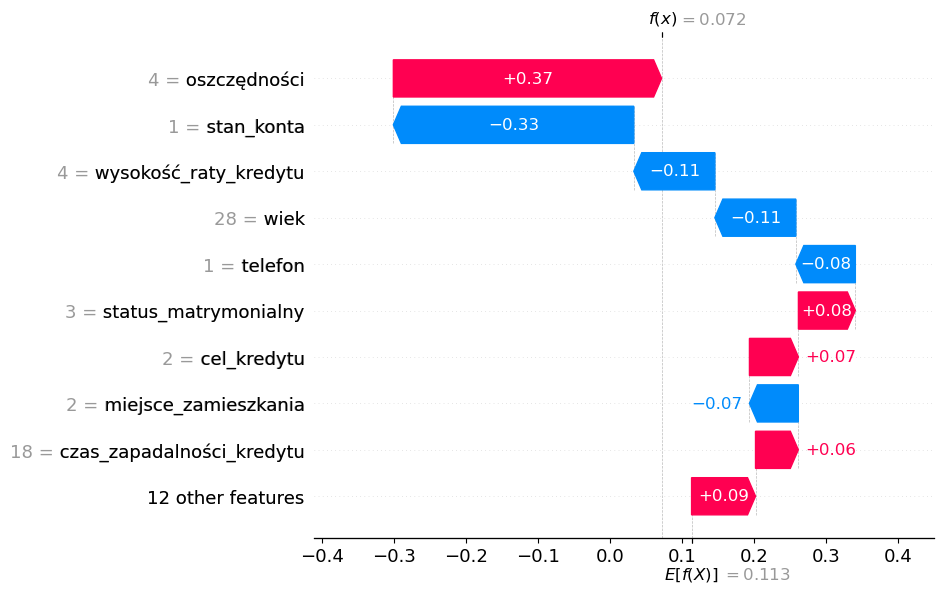

In [399]:
shap.plots.waterfall(svc_shap_values[0], max_display=10, show=True)

In [400]:
from sklearn.metrics import brier_score_loss

In [401]:
y_scores = best_svc.predict(X_test_transformed)

In [402]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.25092250922509224

In [133]:
y_predicted = best_svc.predict(X_test_transformed)

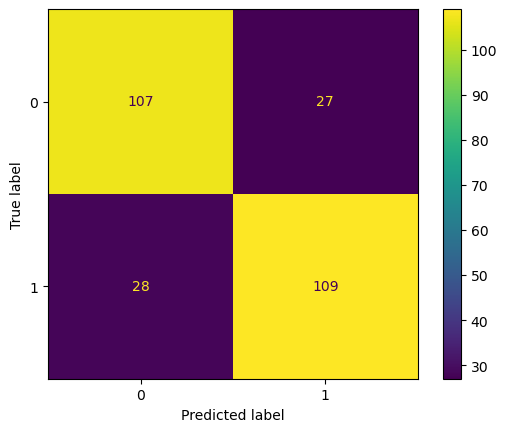

In [134]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [135]:
accuracy_score(y_test, y_predicted)

0.7970479704797048

In [136]:
recall_score(y_test, y_predicted)

0.7956204379562044

In [137]:
precision_score(y_test, y_predicted)

0.8014705882352942

In [138]:
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [139]:
rf = RandomForestClassifier(random_state = 42)

In [140]:
clf_rf = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'cat')),
    ('classifier', RandomForestClassifier(random_state = 42))])

In [551]:
param_distributions = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_split': [10, 20],
    'classifier__min_samples_leaf': [80, 90],
    'classifier__max_features': ['sqrt'],
    'classifier__criterion': ['gini', 'entropy']
}

In [552]:
model_rf = RandomizedSearchCV(clf_rf, 
                              param_distributions = param_distributions, 
                              cv = cv, 
                              n_iter = 5, 
                              n_jobs = -1, 
                              scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                              return_train_score = True, 
                              refit = 'balanced_accuracy', 
                              random_state = 42,
                             error_score = 'raise')

In [553]:
model_rf.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [3, 5, ...], 'classifier__max_features': ['sqrt'], 'classifier__min_samples_leaf': [80, 90], ...}"
,n_iter,5
,scoring,"['recall', 'accuracy', ...]"
,n_jobs,-1
,refit,'balanced_accuracy'
,cv,RepeatedStrat...ndom_state=42)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,'raise'


In [554]:
best_rf = model_rf.best_estimator_

accuracy:  0.7399863457927975
recall:  0.734994161801501
precision:  0.7486527512848657


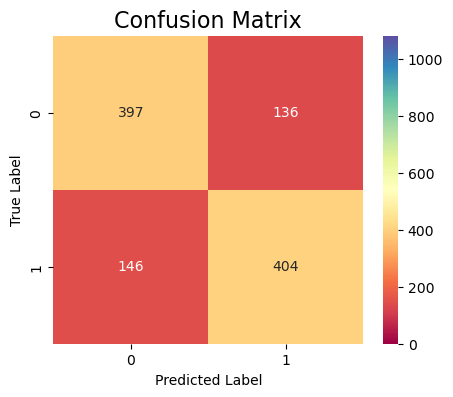

In [555]:
cv_cm(model_rf, y_train)

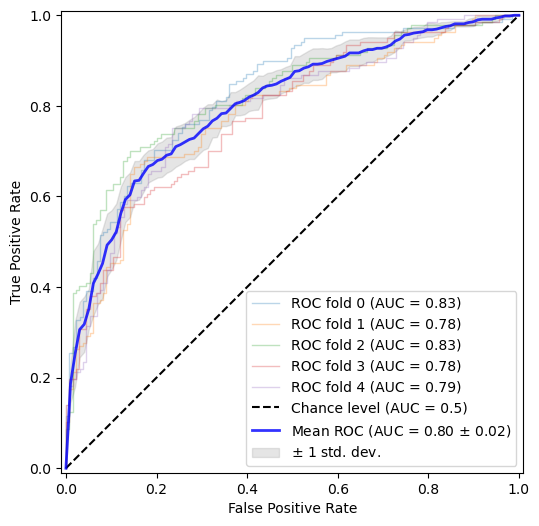

In [556]:
roc_cv(model_rf)

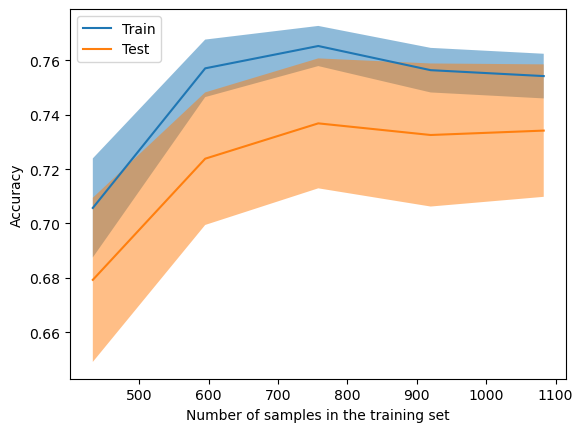

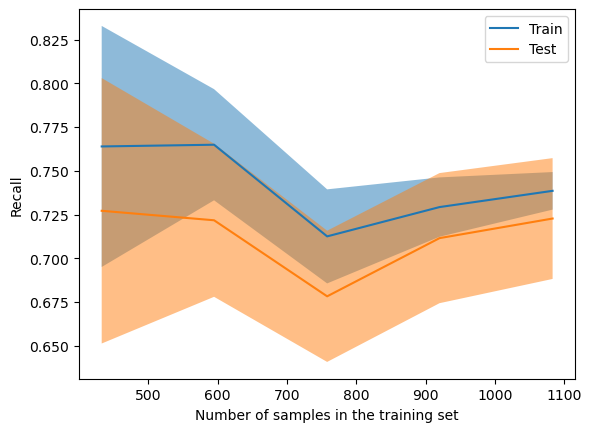

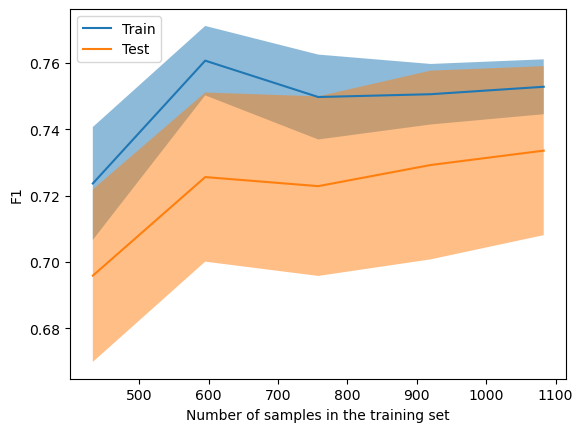

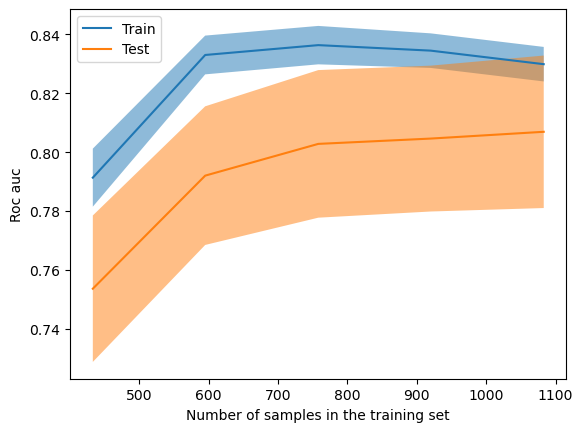

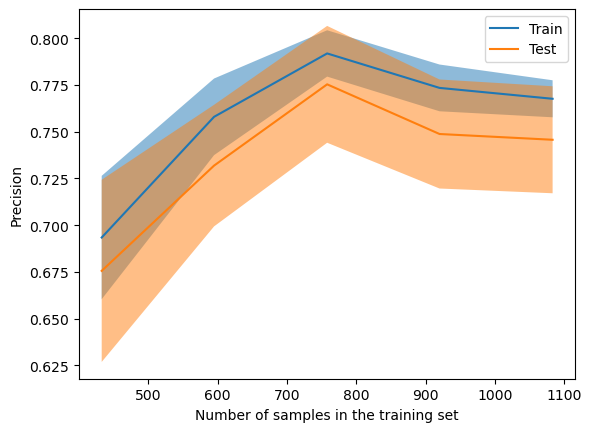

In [557]:
for i in evals:
     display = LearningCurveDisplay.from_estimator(best_rf, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [558]:
model_evaluation(best_rf)

Mean accuracy: 0.7329304359710265
Standard deviation: 0.021710478671913606


Mean recall: 0.7253697238971756
Standard deviation: 0.030641108529511067


Mean f1: 0.7333421592254833
Standard deviation: 0.02249824018380461


Mean roc_auc: 0.8058901558381143
Standard deviation: 0.022693559874395714


Mean precision: 0.7421230449796731
Standard deviation: 0.02273190341022168




In [559]:
best_rf.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [560]:
best_rf = best_rf.named_steps['classifier']

In [561]:
fitted_preprocessor = clf_rf.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [562]:
rf_explainer = shap.TreeExplainer(best_rf, X_train_transformed_df, model_output = 'probability')
rf_shap_values = rf_explainer(X_train_transformed_df)
rf_shap_values = united_shapley(rf_shap_values)

In [563]:
X_train_transformed_df.head(1)

,num__czas_zapadalności_kredytu,num__wielkość_kredytu,num__wiek,num__wielkość kredytu / czas spłaty,cat__stan_konta_1,cat__stan_konta_2,cat__stan_konta_3,cat__stan_konta_4,cat__historia_kredytowa_0,cat__historia_kredytowa_1,...,cat__praca_1,cat__praca_2,cat__praca_3,cat__praca_4,cat__liczba_osób_na_utrzymaniu_1,cat__liczba_osób_na_utrzymaniu_2,cat__telefon_1,cat__telefon_2,cat__cudzoziemiec_1,cat__cudzoziemiec_2
0,18.0,2659.0,28.0,147.722222,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0


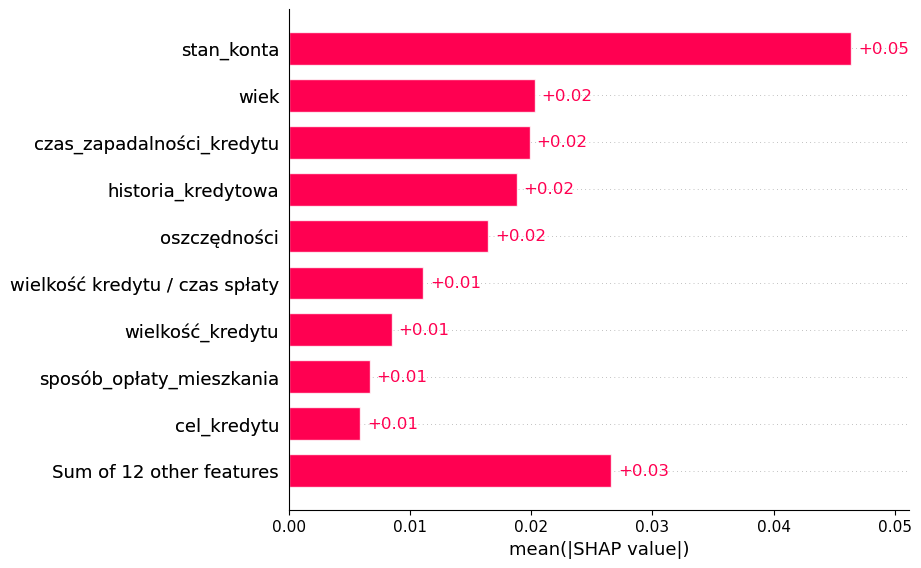

In [564]:
shap.plots.bar(rf_shap_values)

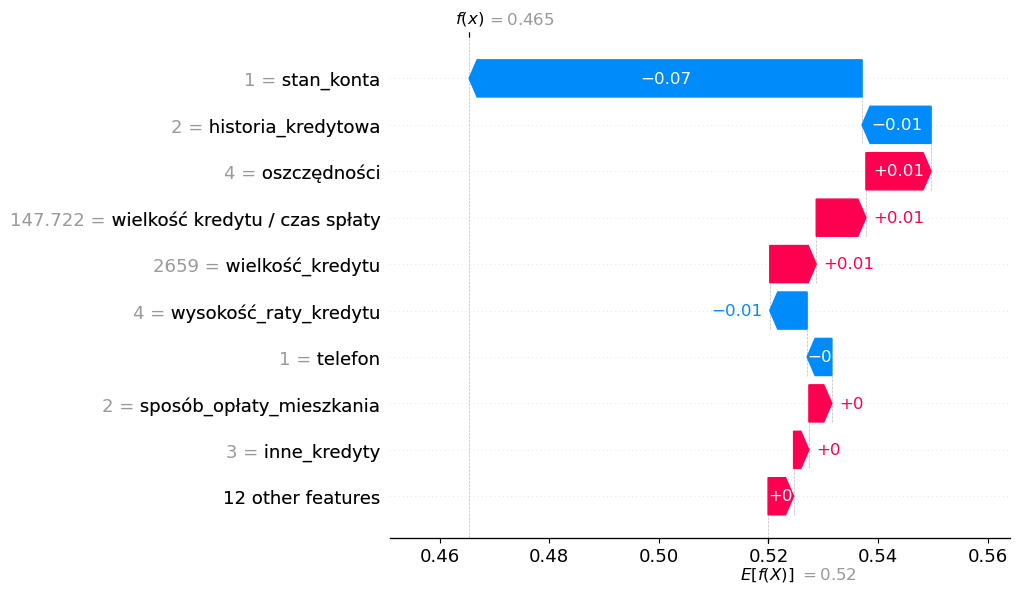

In [565]:
shap.plots.waterfall(rf_shap_values[0], max_display = 10, show=True)

In [566]:
from sklearn.metrics import brier_score_loss

In [567]:
y_scores = best_rf.predict_proba(X_test_transformed)[:, 1]

In [568]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.21470467557130288

In [569]:
y_predicted = best_rf.predict(X_test_transformed)

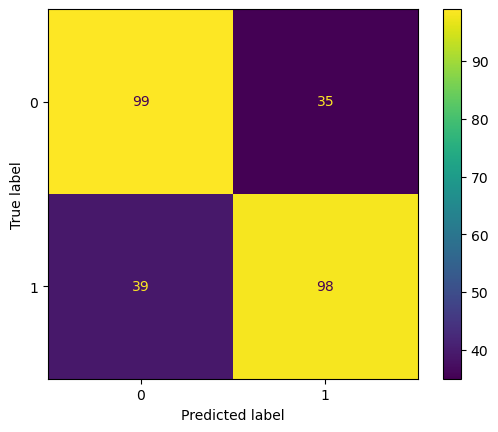

In [570]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [571]:
accuracy_score(y_test, y_predicted)

0.7269372693726938

In [572]:
recall_score(y_test, y_predicted)

0.7153284671532847

In [573]:
precision_score(y_test, y_predicted)

0.7368421052631579

In [574]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [165]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC

clf_xgb = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'cat')),
                            ('classifier', XGBClassifier(random_state = 42, enable_categorical = True))])

In [649]:
param_distribution = {
    'classifier__max_depth': [2, 3], 
    'classifier__min_child_weight': [10, 15, 20], 
    'classifier__lambda': [50, 70, 80], 
    'classifier__alpha': [1, 5],
    'classifier__learning_rate': [0.01, 0.02, 0.05],
    'classifier__n_estimators': [400, 600],
    'classifier__subsample': [0.7, 0.8],
    'classifier__colsample_bytree': [0.7, 0.8],
    'classifier__gamma': [1, 2]
}

In [650]:
model_xgb = RandomizedSearchCV(clf_xgb, param_distributions = param_distribution, n_iter = 10, scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], refit = 'f1_weighted', n_jobs = -1, cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42), random_state = 42, error_score = 'raise')

In [651]:
model_xgb.fit(X_train, y_train)

,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__alpha': [1, 5], 'classifier__colsample_bytree': [0.7, 0.8], 'classifier__gamma': [1, 2], 'classifier__lambda': [50, 70, ...], ...}"
,n_iter,10
,scoring,"['recall', 'accuracy', ...]"
,n_jobs,-1
,refit,'f1_weighted'
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,'raise'


In [652]:
best_xgb = model_xgb.best_estimator_

In [653]:
y_scores = best_xgb.predict_proba(X_test)[:, 1]

accuracy:  0.7424219150025602
recall:  0.7413344453711426
precision:  0.7533541504236796


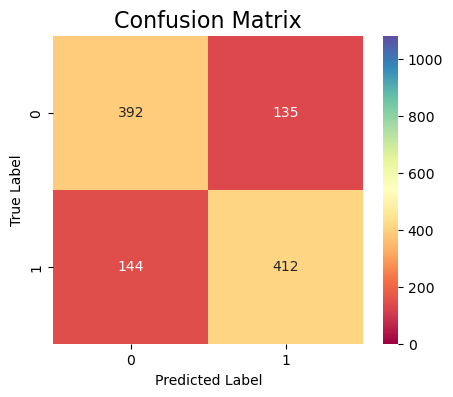

In [654]:
cv_cm(model_xgb, y_train)

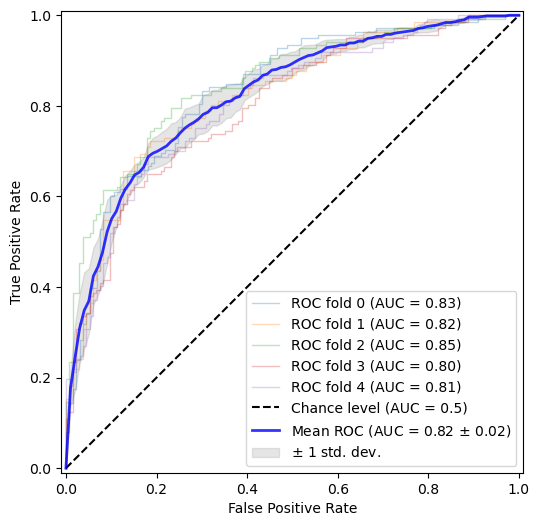

In [655]:
roc_cv(model_xgb)

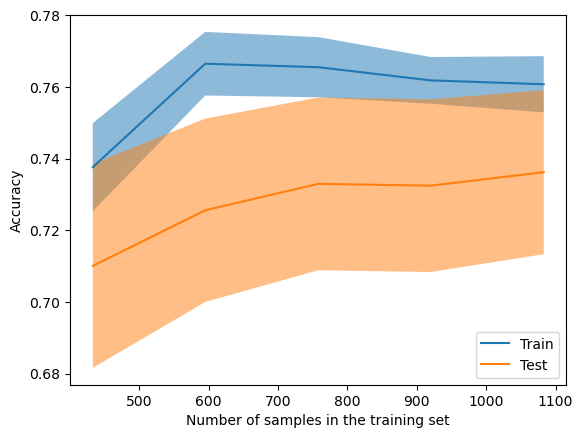

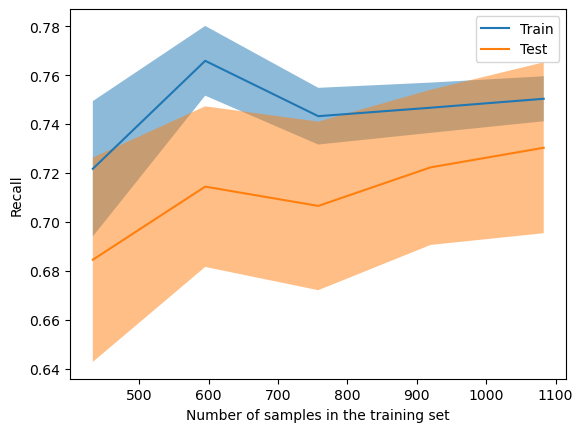

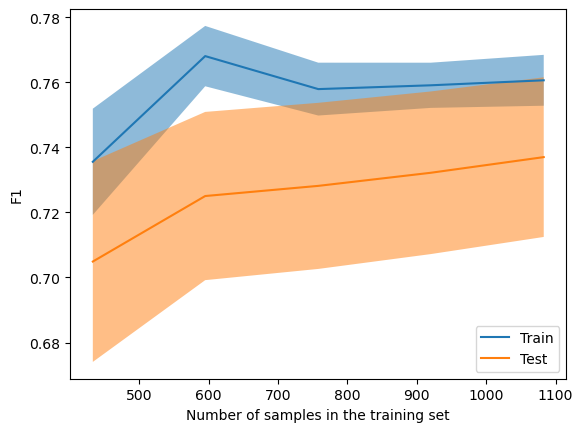

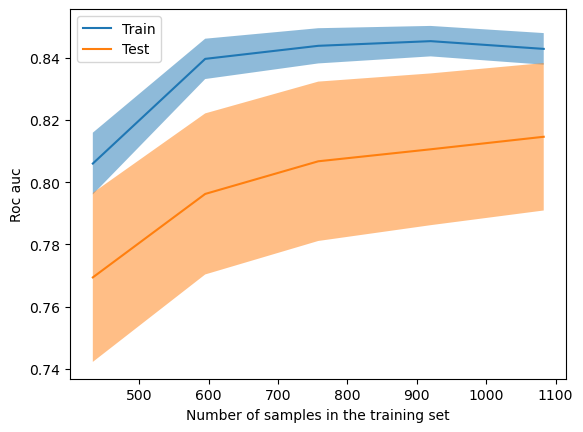

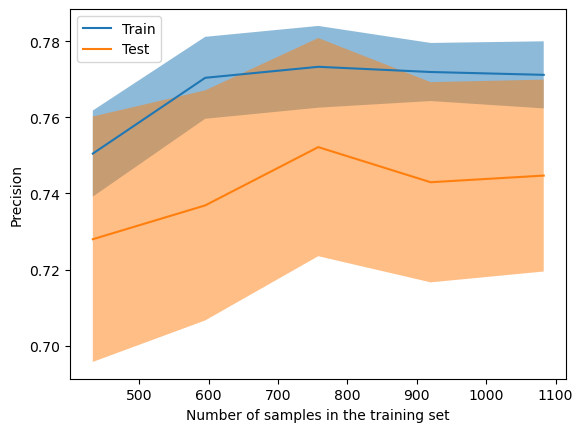

In [656]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_xgb, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [657]:
model_evaluation(best_xgb)

Mean accuracy: 0.7333808938089382
Standard deviation: 0.022931641065308962


Mean recall: 0.7279974611234529
Standard deviation: 0.031472072334824554


Mean f1: 0.7343823005424364
Standard deviation: 0.023690860643214316


Mean roc_auc: 0.8139864399271268
Standard deviation: 0.021059903962359582


Mean precision: 0.7415305517202033
Standard deviation: 0.024091651450982788




In [658]:
best_xgb = best_xgb.named_steps['classifier']

In [659]:
fitted_preprocessor = clf_xgb.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

In [660]:
feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [661]:
xgb_explainer = shap.TreeExplainer(best_xgb, X_train_transformed_df, model_output = 'probability')

In [662]:
xgb_shap_values_ohe = xgb_explainer(X_train_transformed_df)

In [663]:
xgb_shap_values_ohe = united_shapley(xgb_shap_values_ohe)

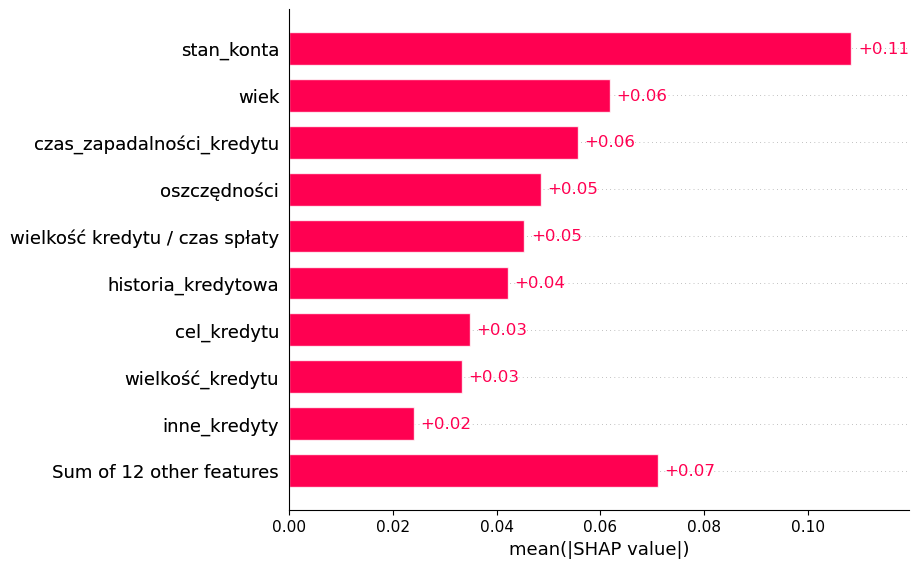

In [664]:
shap.plots.bar(xgb_shap_values_ohe)

In [665]:
X_train.head(1)

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,wielkość kredytu / czas spłaty
1,1,18,2,2,2659,4,3,4,3,1,...,3,28,3,2,1,3,2,1,2,147.722222


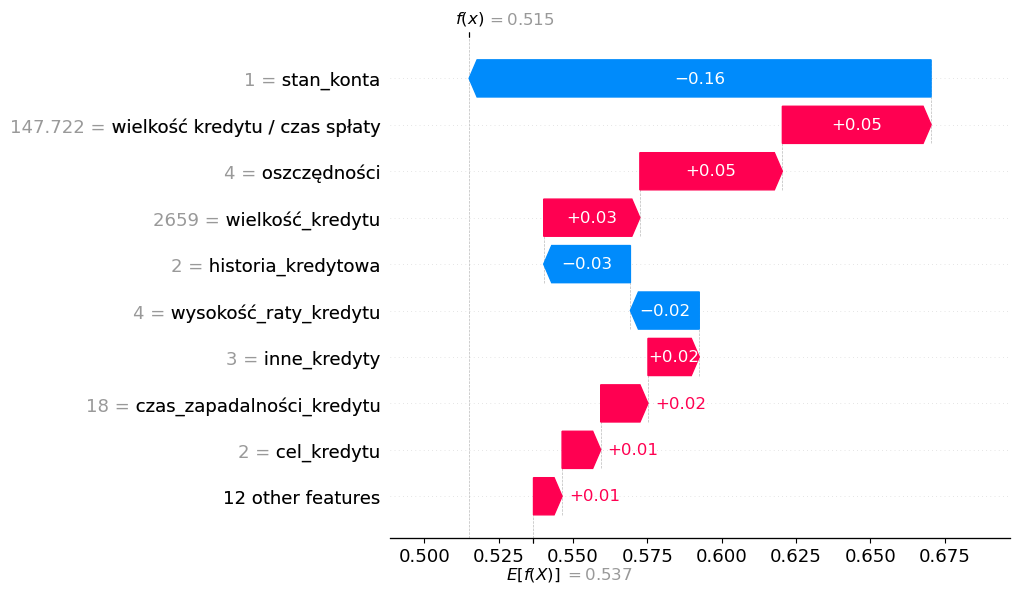

In [666]:
shap.plots.waterfall(xgb_shap_values_ohe[0], max_display = 10, show=True)

In [667]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.18445224431899876

In [668]:
y_predicted = best_xgb.predict(X_test_transformed)

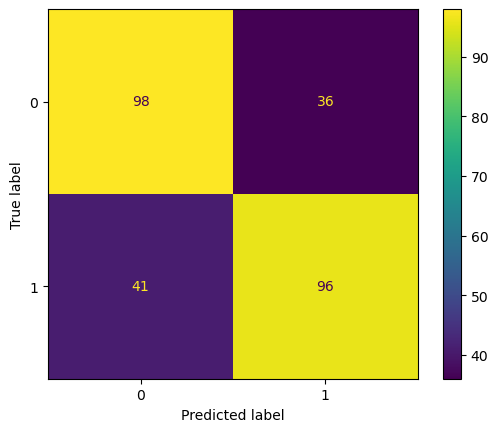

In [669]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [670]:
accuracy_score(y_test, y_predicted)

0.7158671586715867

In [671]:
recall_score(y_test, y_predicted)

0.7007299270072993

In [672]:
precision_score(y_test, y_predicted)

0.7272727272727273